In [1]:
# Import pandas to load and work with the CSV dataset
import pandas as pd

# Import train_test_split to divide the dataset
# into training and testing sets
from sklearn.model_selection import train_test_split

# Import KNeighborsClassifier
# This is the K-Nearest Neighbors (KNN) algorithm
from sklearn.neighbors import KNeighborsClassifier

In [2]:
# Load the training dataset
# Make sure train.csv is in the same folder as this notebook
train_data = pd.read_csv("../data/train.csv")

# Display the shape of the dataset
# Expected output: (42000, 785)
print("Training data shape:", train_data.shape)

Training data shape: (42000, 785)


In [3]:
# X contains the pixel values of the handwritten digit images
# We remove the 'label' column because it is the target/output
X = train_data.drop("label", axis=1)

# y contains the actual digit labels
# The labels are numbers from 0 to 9
y = train_data["label"]

# Display the shapes
print("Features shape:", X.shape)
print("Labels shape:", y.shape)

Features shape: (42000, 784)
Labels shape: (42000,)


In [4]:
    # The original pixel values range from 0 to 255.
# Divide every pixel by 255 to convert the values
# into the range 0 to 1.
X = X / 255.0

# Check the minimum pixel value
print("Minimum pixel value:", X.min().min())

# Check the maximum pixel value
print("Maximum pixel value:", X.max().max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [5]:
# Split the dataset into training and testing portions
X_train, X_test, y_train, y_test = train_test_split(
    X,                  # Pixel data
    y,                  # Digit labels
    test_size=0.2,      # 20% of the data is used for testing
    random_state=42,    # Makes the split reproducible
    stratify=y          # Keeps the digit distribution balanced
)

# Display the resulting shapes
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (33600, 784)
X_test : (8400, 784)
y_train: (33600,)
y_test : (8400,)


In [6]:
# Create the K-Nearest Neighbors classifier
knn_model = KNeighborsClassifier(
    n_neighbors=5,       # Use the 5 nearest training images
    weights="distance",  # Give closer neighbors more importance
    n_jobs=-1            # Use all available CPU cores
)

# Display the model configuration
print(knn_model)

KNeighborsClassifier(n_jobs=-1, weights='distance')


In [7]:
# Train the KNN model using the training data
# KNN does not build a complex mathematical model like MLP.
# Instead, it stores the training examples and uses them
# when making predictions.
knn_model.fit(X_train, y_train)

# Display a message after training
print("KNN training completed successfully!")

KNN training completed successfully!


In [8]:
# Use the trained KNN model to predict
# the digits in the test dataset
y_pred_knn = knn_model.predict(X_test)

# Display the first 10 predictions
print("First 10 KNN predictions:", y_pred_knn[:10])

First 10 KNN predictions: [1 8 6 9 5 7 6 7 7 7]


In [9]:
# Import the evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Calculate the overall accuracy
knn_accuracy = accuracy_score(y_test, y_pred_knn)

# Calculate weighted precision for the 10 digit classes
knn_precision = precision_score(
    y_test,
    y_pred_knn,
    average="weighted"
)

# Calculate weighted recall
knn_recall = recall_score(
    y_test,
    y_pred_knn,
    average="weighted"
)

# Calculate weighted F1-score
knn_f1 = f1_score(
    y_test,
    y_pred_knn,
    average="weighted"
)

# Display all four evaluation metrics
print("KNN Accuracy :", knn_accuracy)
print("KNN Precision:", knn_precision)
print("KNN Recall   :", knn_recall)
print("KNN F1-Score :", knn_f1)

KNN Accuracy : 0.9677380952380953
KNN Precision: 0.9681661788671482
KNN Recall   : 0.9677380952380953
KNN F1-Score : 0.9676700804383749


In [10]:
# Error rate represents the proportion of
# test images classified incorrectly
knn_error_rate = 1 - knn_accuracy

# Calculate the number of incorrect predictions
knn_incorrect = (y_test != y_pred_knn).sum()

# Calculate the number of correct predictions
knn_correct = (y_test == y_pred_knn).sum()

# Display the results
print("KNN Error Rate:", knn_error_rate)
print("KNN Error Rate (%):", knn_error_rate * 100)

print("Correct predictions:", knn_correct)
print("Incorrect predictions:", knn_incorrect)

# Display the total number of test samples
print("Total predictions:", len(y_test))

KNN Error Rate: 0.032261904761904714
KNN Error Rate (%): 3.2261904761904714
Correct predictions: 8129
Incorrect predictions: 271
Total predictions: 8400


In [11]:
# Import classification_report
from sklearn.metrics import classification_report

# Generate the classification report
# for digits 0 through 9
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       827
           1       0.95      1.00      0.98       937
           2       0.99      0.96      0.97       835
           3       0.96      0.96      0.96       870
           4       0.98      0.96      0.97       814
           5       0.96      0.97      0.96       759
           6       0.98      0.99      0.98       827
           7       0.97      0.97      0.97       880
           8       0.99      0.91      0.95       813
           9       0.93      0.97      0.95       838

    accuracy                           0.97      8400
   macro avg       0.97      0.97      0.97      8400
weighted avg       0.97      0.97      0.97      8400



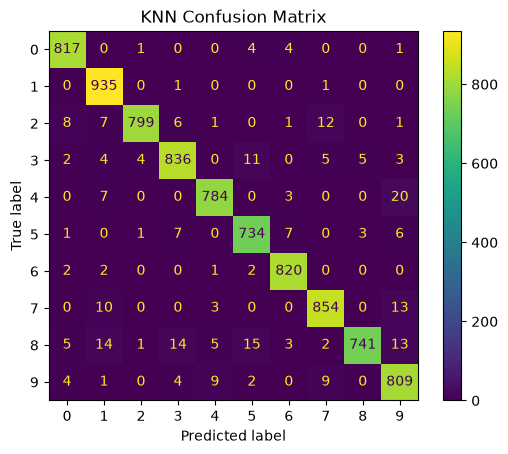

In [12]:
# Import confusion matrix tools
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Import matplotlib for displaying the graph
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred_knn)

# Create a visual representation of the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

# Display the confusion matrix
disp.plot()

# Add a title
plt.title("KNN Confusion Matrix")

# Display the graph
plt.show()

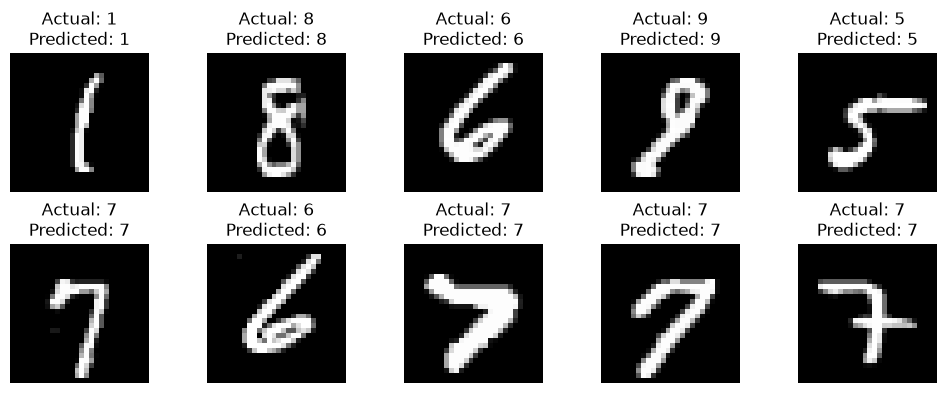

In [13]:
# Create a figure for displaying 10 test images
plt.figure(figsize=(10, 4))

# Display the first 10 test images
for i in range(10):

    # Convert the 784 pixel values back into
    # a 28 × 28 image
    image = X_test.iloc[i].values.reshape(28, 28)

    # Create a subplot
    plt.subplot(2, 5, i + 1)

    # Display the handwritten digit
    plt.imshow(image, cmap="gray")

    # Display the actual and predicted labels
    plt.title(
        f"Actual: {y_test.iloc[i]}\n"
        f"Predicted: {y_pred_knn[i]}"
    )

    # Hide the axis
    plt.axis("off")

# Adjust the spacing
plt.tight_layout()

# Display the images
plt.show()

In [14]:
# Import joblib for saving the trained KNN model
import joblib

# Save the KNN model to a file
joblib.dump(knn_model, "knn_digit_model.pkl")

# Confirm that the model has been saved
print("KNN model saved successfully!")

KNN model saved successfully!
